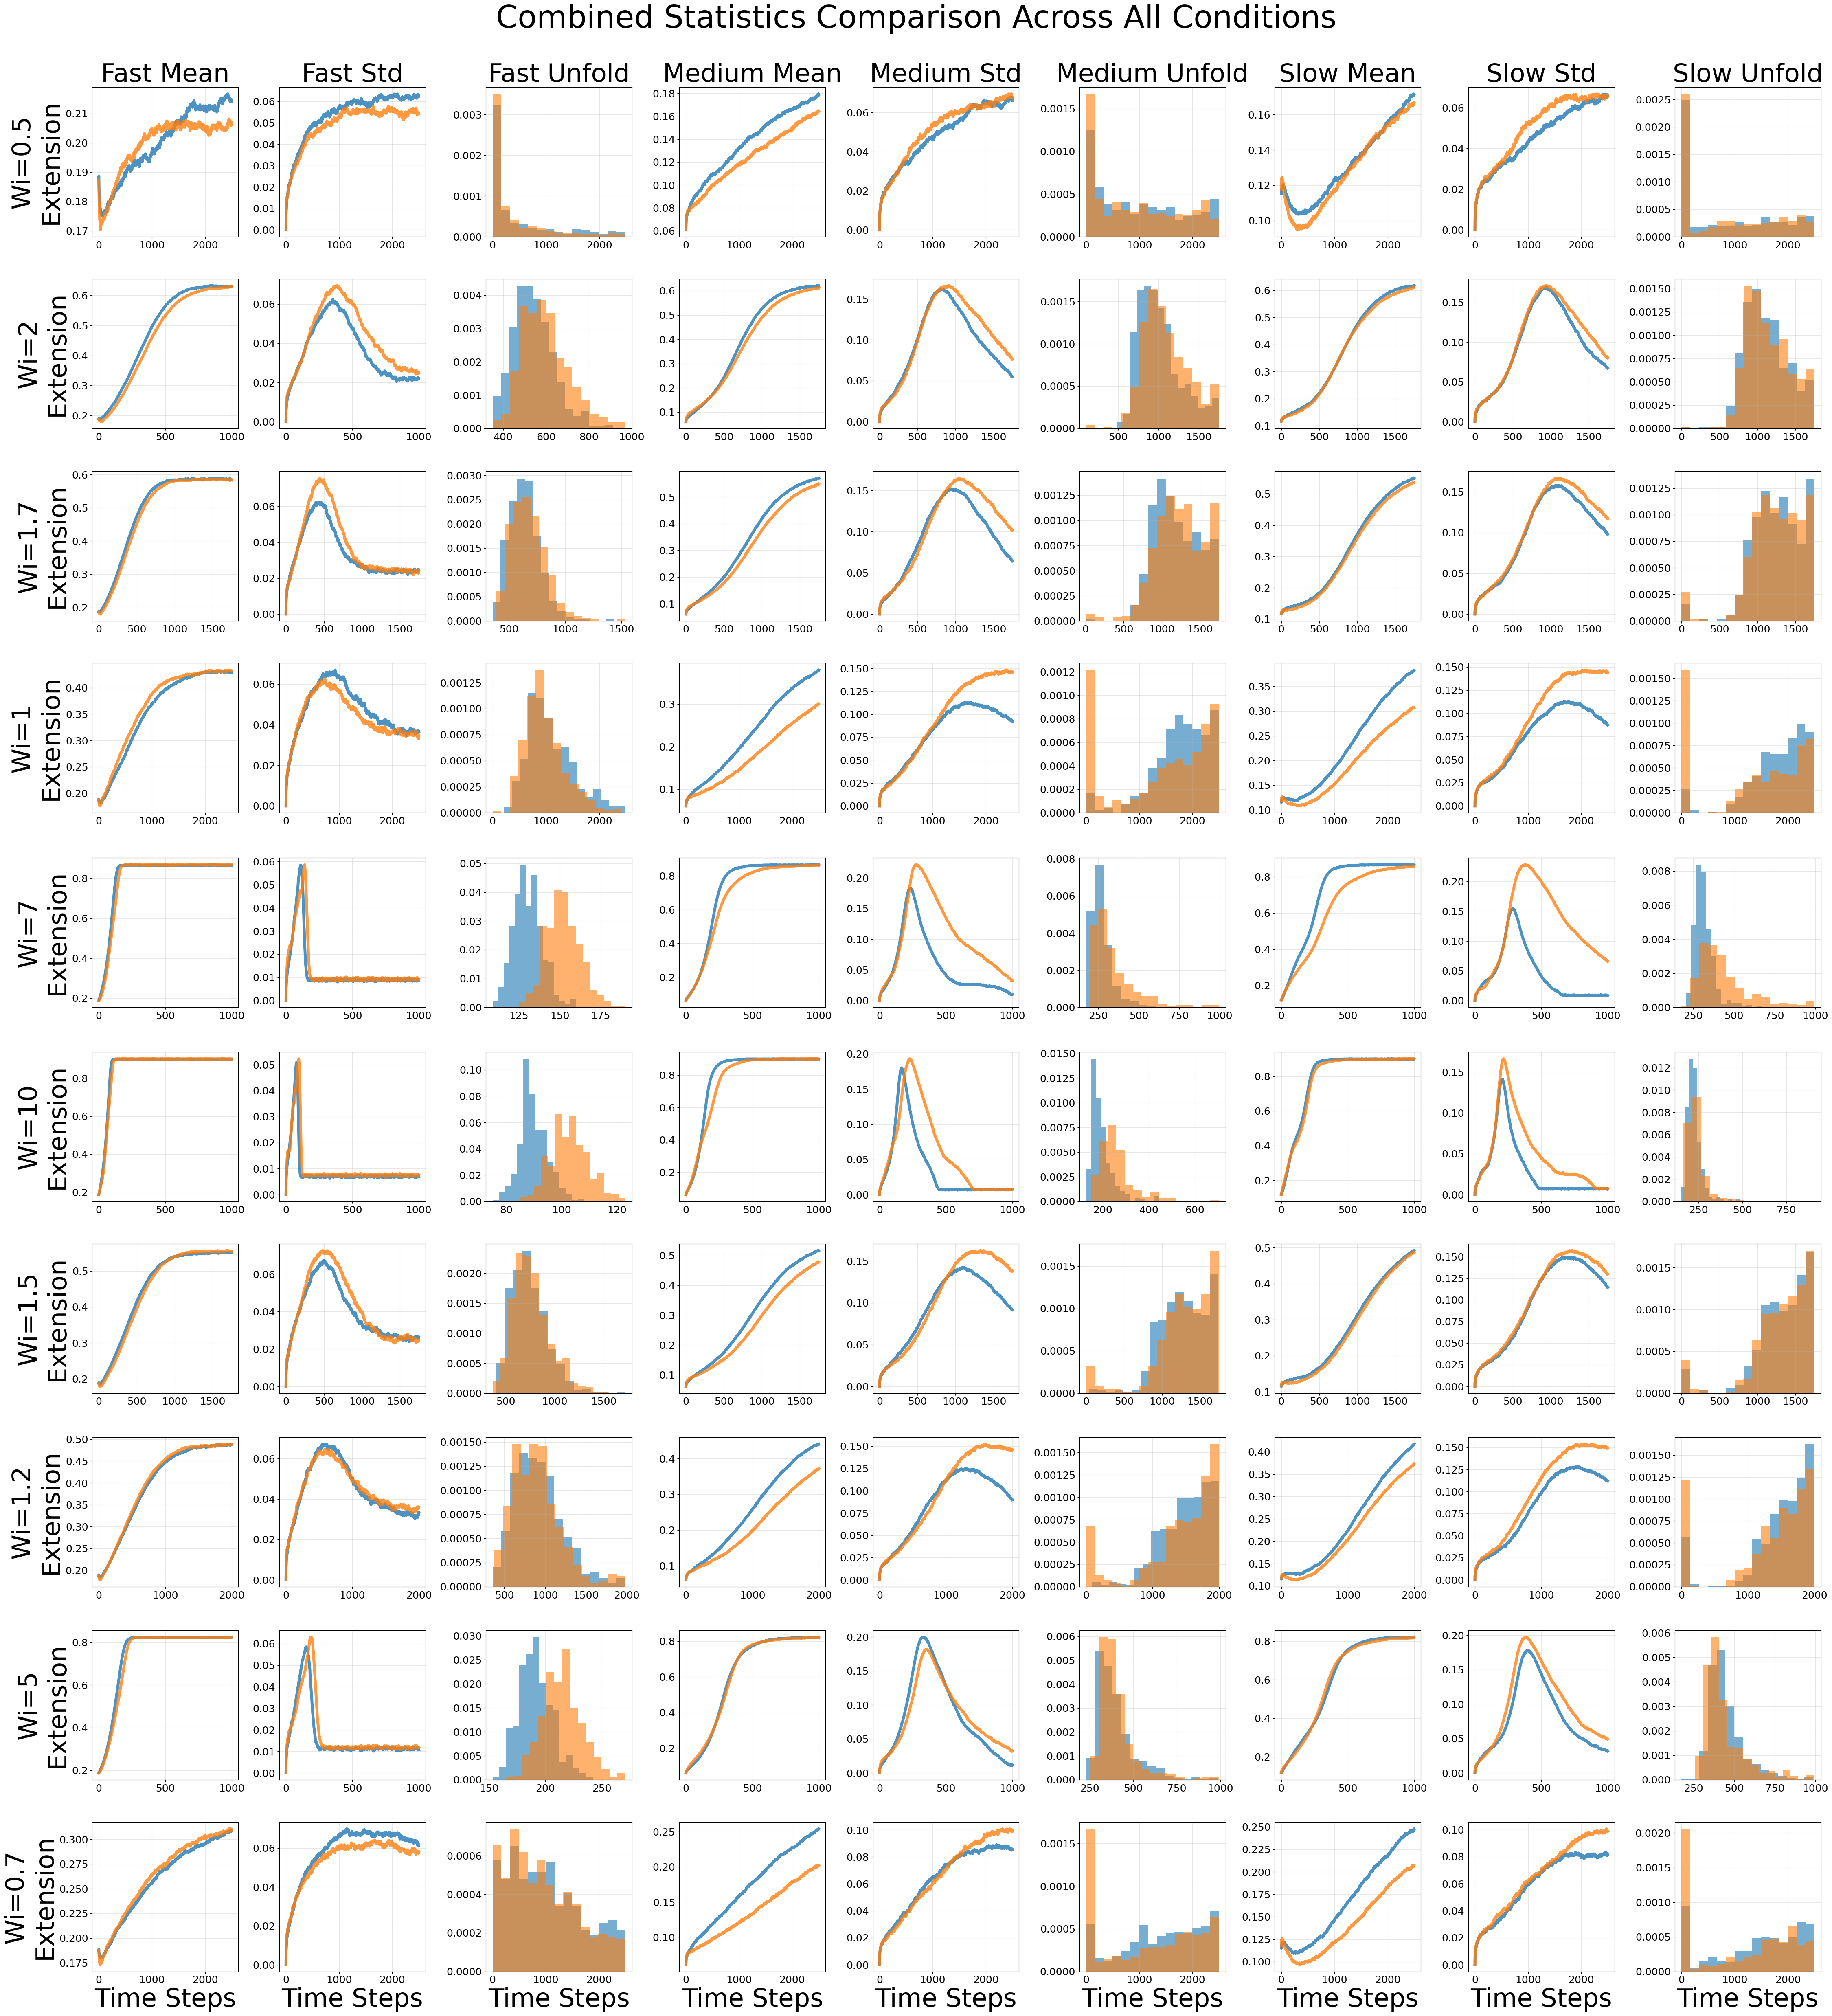

In [1]:
# Redraw the combined statistics figure of ../polymer_dynamics_wi_symm_analysis.ipynb from the
# npz that notebook saved. Needs no model, data or simulation.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plot_file = Path("../symm_analysis_stats_2026_02_14-15_31_11.npz")   # saved next to the analysis notebook
d = np.load(plot_file)
splits = list(d["splits"])            # rows, in the order of the original figure
conditions = list(d["conditions"])    # fast / middle / slow
cond_names = ["Fast", "Medium", "Slow"]

# font sizes (pt); panel size and the gaps between panels (inches)
FS = dict(suptitle=55, col_title=45, row_label=45, xlabel=45, tick=18, legend=16)
PANEL = 5
W_PAD, H_PAD = 0.1, 0.35

fig, axes = plt.subplots(len(splits), 9, figsize=(9 * PANEL, len(splits) * PANEL),
                         squeeze=False, layout="constrained")   # constrained layout makes room for the suptitle
fig.get_layout_engine().set(w_pad=W_PAD, h_pad=H_PAD)
for i, split in enumerate(splits):
    for j, cond in enumerate(conditions):
        p = f"{split}_{cond}/"
        ax_mean, ax_std, ax_unf = axes[i, 3 * j : 3 * j + 3]
        # x is the step index, as in the original; use d[p + "t"] to plot against time
        for ax, stat in ((ax_mean, "mean"), (ax_std, "std")):
            ax.plot(d[p + f"true_{stat}"][:, 0], label="True", alpha=0.8, linewidth=5)
            ax.plot(d[p + f"pred_{stat}"][:, 0], label="Pred", alpha=0.8, linewidth=5)
        ax_unf.hist(d[p + "true_unfold_step"], label="True", alpha=0.6, density=True, bins=15)
        ax_unf.hist(d[p + "pred_unfold_step"], label="Pred", alpha=0.6, density=True, bins=15)
        for ax in (ax_mean, ax_std, ax_unf):
            # ax.legend(fontsize=FS["legend"])
            ax.grid(True, alpha=0.3)
            ax.tick_params(labelsize=FS["tick"])
            ax.yaxis.get_offset_text().set_fontsize(FS["tick"])
    wi = d[f"{split}_{conditions[0]}/args"][1]   # args = (T, Wi)
    axes[i, 0].set_ylabel(f"Wi={wi:g}\nExtension", fontsize=FS["row_label"] )

col_labels = [f"{n} {m}" for n in cond_names for m in ("Mean", "Std", "Unfold")]
for j, label in enumerate(col_labels):
    axes[0, j].set_title(label, fontsize=FS["col_title"] )
for j in range(9):
    axes[-1, j].set_xlabel("Time Steps", fontsize=FS["xlabel"])

fig.suptitle("Combined Statistics Comparison Across All Conditions", fontsize=FS["suptitle"])
fig.savefig(plot_file.with_suffix(".pdf").name, dpi=100)   # png goes next to this notebook
plt.show()